## Lab - EDA Bivariate Analysis: Diving into Amazon UK Product Insights Part II

**Objective**: Delve into the dynamics of product pricing on Amazon UK to uncover insights that can inform business strategies and decision-making.

**Dataset**: This lab utilizes the [Amazon UK product dataset](https://www.kaggle.com/datasets/asaniczka/uk-optimal-product-price-prediction/)
which provides information on product categories, brands, prices, ratings, and more from from Amazon UK. You'll need to download it to start working with it.


### Part 1: Analyzing Best-Seller Trends Across Product Categories

**Objective**: Understand the relationship between product categories and their best-seller status.

1. **Crosstab Analysis**:
    - Create a crosstab between the product `category` and the `isBestSeller` status.
    
    - Are there categories where being a best-seller is more prevalent? 
    	
    	*Hint: one option is to calculate the proportion of best-sellers for each category and then sort the categories based on this proportion in descending order.*


2. **Statistical Tests**:
    - Conduct a Chi-square test to determine if the best-seller distribution is independent of the product category.
    - Compute Cramér's V to understand the strength of association between best-seller status and category.

3. **Visualizations**:
	- Visualize the relationship between product categories and the best-seller status using a stacked bar chart.

In [54]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [37]:
df = pd.read_csv("amz_uk_price_prediction_dataset.csv")
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [38]:
df_cross = pd.crosstab(df['category'],df['isBestSeller'])
df_cross.columns.name = None
df_cross.index.name = None
df_cross['porpotion'] = df_cross[True]/(df_cross[True]+df_cross[False])
df_cross = df_cross.sort_values(by='porpotion',ascending=False)
#df_cross.reset_index()
df_cross

,False,True,porpotion
Grocery,9008,556,0.058135
Smart Home Security & Lighting,98,6,0.057692
Health & Personal Care,9017,552,0.057686
Mobile Phone Accessories,248,11,0.042471
Power & Hand Tools,8353,306,0.035339
...,...,...,...
"CD, Disc & Tape Players",8798,0,0.000000
General Music-Making Accessories,259,0,0.000000
Snowboard Boots,1449,0,0.000000
Boxes & Organisers,911,0,0.000000


### Null Hypothesis (H₀)

Best-seller status is independent of product category.

### Alternative Hypothesis (H₁)

Best-seller status is associated with product category.

In [39]:
from scipy.stats import chi2_contingency

df_cross1 = pd.crosstab(df['category'],df['isBestSeller'])
chi2, p, dof, expected = chi2_contingency(df_cross1)

print(f"Chi-square Statistic: {chi2:.4f}")
print(f"P-value: {p:.4f}")
print(f"Degrees of Freedom: {dof}")


Chi-square Statistic: 36540.2027
P-value: 0.0000
Degrees of Freedom: 295


Reject the null hypothesis. There is a statistically significant association between product category and best-seller status.

In [40]:
n = df_cross1.sum().sum()

k = min(df_cross.shape)

cramers_v = np.sqrt(
    chi2 / (n * (k - 1))
)

print(f"Cramer's V: {cramers_v:.4f}")

Cramer's V: 0.0865


Although the association is statistically significant, its practical strength is negligible.

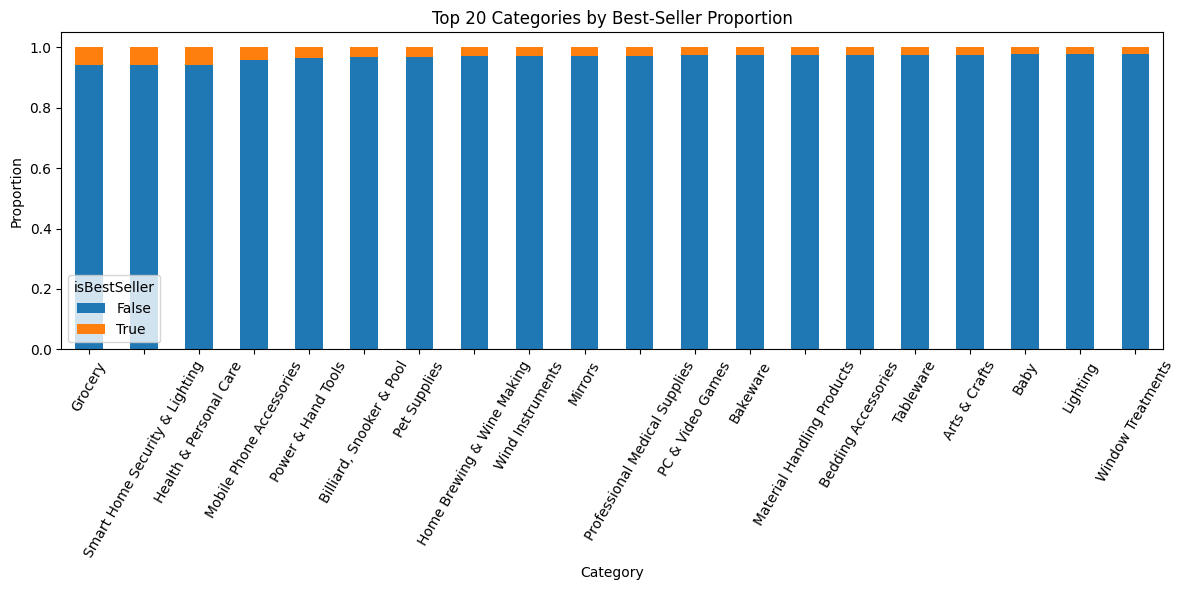

In [41]:
df_prop = pd.crosstab(
    df['category'],
    df['isBestSeller'],
    normalize='index'
)

top20 = df_prop.sort_values(
    by=True,
    ascending=False
).head(20)

top20.plot(
    kind='bar',
    stacked=True,
    figsize=(12,6)
)

plt.title('Top 20 Categories by Best-Seller Proportion')
plt.ylabel('Proportion')
plt.xlabel('Category')
plt.xticks(rotation=60)
plt.tight_layout()
plt.show()

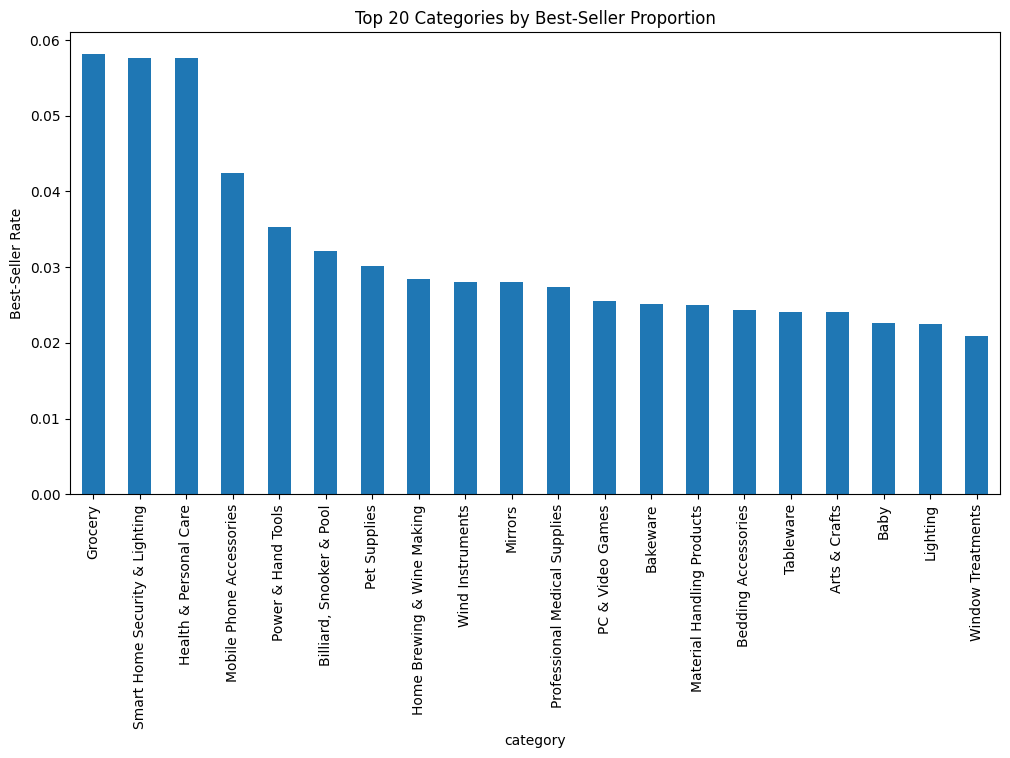

In [42]:
best_prop = (
    pd.crosstab(df['category'], df['isBestSeller'])
    .assign(proportion=lambda x: x[True] / x.sum(axis=1))
    .sort_values('proportion', ascending=False)
    .head(20)
)

best_prop['proportion'].plot(
    kind='bar',
    figsize=(12,6)
)

plt.title('Top 20 Categories by Best-Seller Proportion')
plt.ylabel('Best-Seller Rate')
plt.show()

### Part 2: Exploring Product Prices and Ratings Across Categories and Brands

**Objective**: Investigate how different product categories influence product prices.

0. **Preliminary Step: Remove outliers in product prices.**

	For this purpose, we can use the IQR (Interquartile Range) method. Products priced below the first quartile minus 1.5 times the IQR or above the third quartile plus 1.5 times the IQR will be considered outliers and removed from the dataset. The next steps will be done with the dataframe without outliers.
	
	*Hint: you can check the last Check For Understanding at the end of the lesson EDA Bivariate Analysis for a hint on how to do this.*

1. **Violin Plots**:
    - Use a violin plot to visualize the distribution of `price` across different product `categories`. Filter out the top 20 categories based on count for better visualization.
    - Which product category tends to have the highest median price? Don't filter here by top categories.

2. **Bar Charts**:
    - Create a bar chart comparing the average price of products for the top 10 product categories (based on count).
    - Which product category commands the highest average price? Don't filter here by top categories.

3. **Box Plots**:
    - Visualize the distribution of product `ratings` based on their `category` using side-by-side box plots. Filter out the top 10 categories based on count for better visualization.
    - Which category tends to receive the highest median rating from customers? Don't filter here by top categories.

In [43]:
Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

df_no_outliers = df[
    (df['price'] >= lower) &
    (df['price'] <= upper)
]

print(df.shape)
print(df_no_outliers.shape)

(2443651, 9)
(2115963, 9)


In [44]:
top20 = (
    df_no_outliers['category']
    .value_counts()
    .head(20)
    .index
)

df_top20 = df_no_outliers[
    df_no_outliers['category'].isin(top20)
]

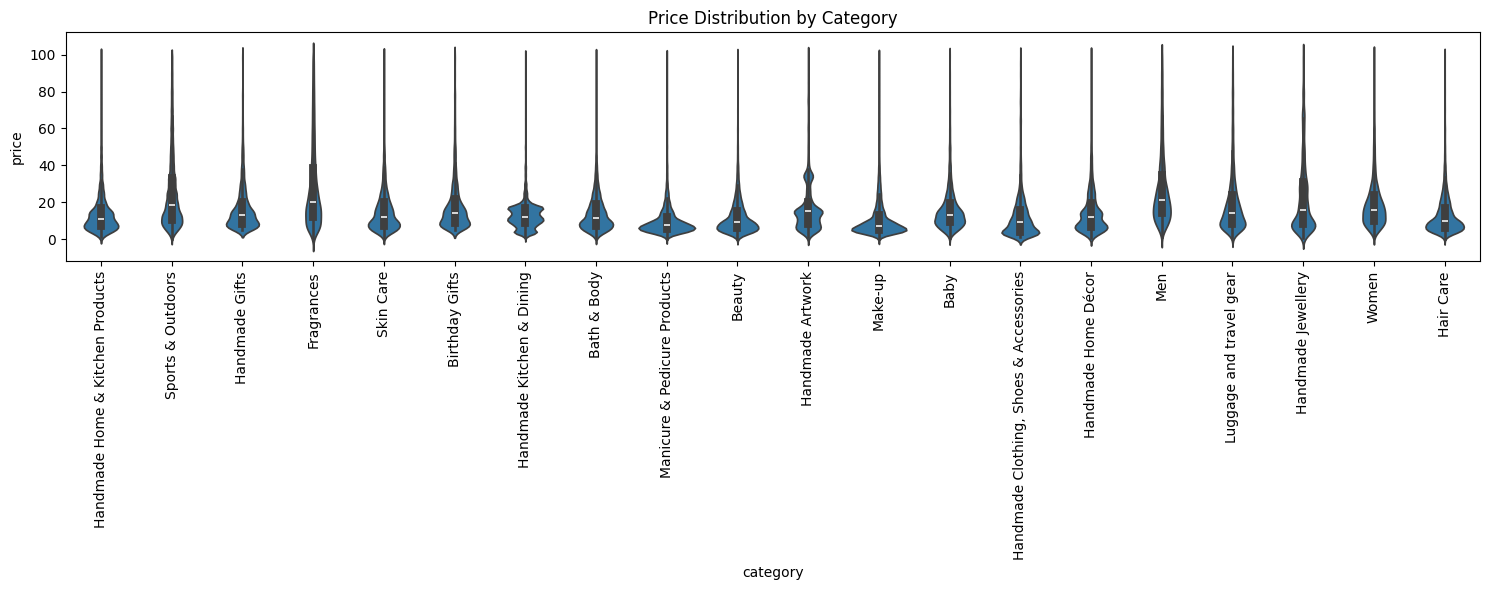

In [45]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(15,6))

sns.violinplot(
    data=df_top20,
    x='category',
    y='price'
)

plt.xticks(rotation=90)
plt.title('Price Distribution by Category')
plt.tight_layout()
plt.show()

In [46]:
median_price = (
    df_no_outliers
    .groupby('category')['price']
    .median()
    .sort_values(ascending=False)
)

median_price.head()

category
Desktop PCs       74.00
Boxing Shoes      69.79
Tablets           69.00
Graphics Cards    68.54
Motherboards      67.92
Name: price, dtype: float64

In [47]:
highest_median_category = median_price.idxmax()

print(highest_median_category)

Desktop PCs


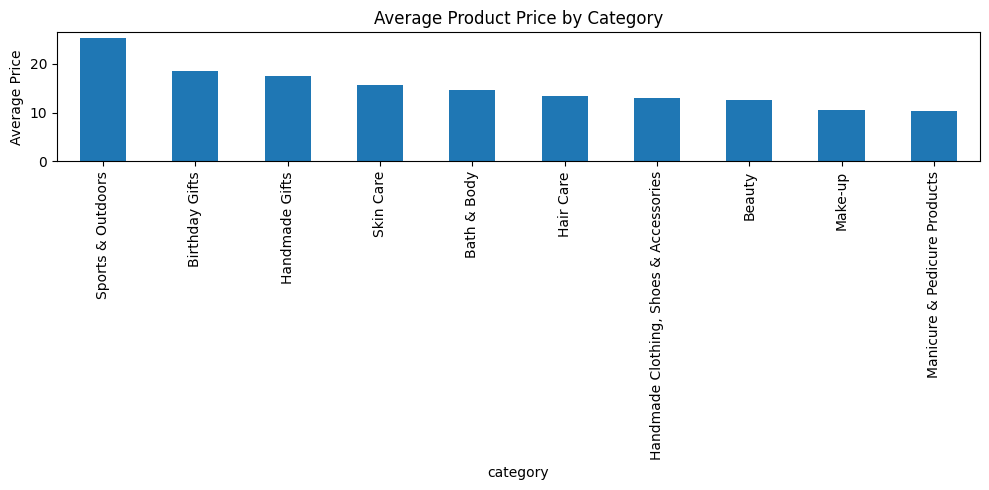

In [48]:
top10 = (
    df_no_outliers['category']
    .value_counts()
    .head(10)
    .index
)

avg_price = (
    df_no_outliers[
        df_no_outliers['category'].isin(top10)
    ]
    .groupby('category')['price']
    .mean()
    .sort_values(ascending=False)
)

avg_price.plot(
    kind='bar',
    figsize=(10,5)
)

plt.title('Average Product Price by Category')
plt.ylabel('Average Price')
plt.tight_layout()
plt.show()

In [49]:
avg_price_all = (
    df_no_outliers
    .groupby('category')['price']
    .mean()
    .sort_values(ascending=False)
)

avg_price_all.head()

category
Motherboards      68.772432
Boxing Shoes      67.417803
Desktop PCs       66.915562
Tablets           66.552971
Graphics Cards    65.103509
Name: price, dtype: float64

In [50]:
avg_price_all.idxmax()

'Motherboards'

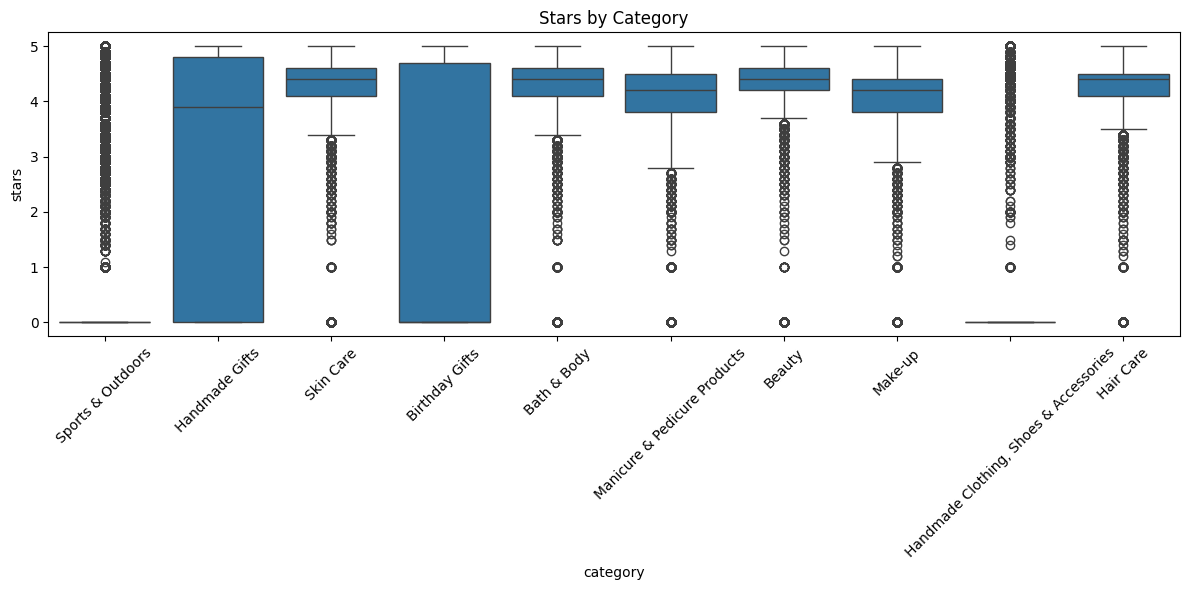

In [58]:
top10 = (
    df_no_outliers['category']
    .value_counts()
    .head(10)
    .index
)

df_top10 = df_no_outliers[
    df_no_outliers['category'].isin(top10)
]

plt.figure(figsize=(12,6))

sns.boxplot(
    data=df_top10,
    x='category',
    y='stars'
)

plt.xticks(rotation=45)
plt.title('Stars by Category')
plt.tight_layout()
plt.show()

In [61]:
median_rating = (
    df_no_outliers
    .groupby('category')['stars']
    .median()
    .sort_values(ascending=False)
)

median_rating.head()

category
Computer Memory                 4.7
Building & Construction Toys    4.6
Office Paper Products           4.6
Luxury Food & Drink             4.6
Kids' Play Figures              4.6
Name: stars, dtype: float64

In [62]:
median_rating.idxmax()

'Computer Memory'

### Part 3: Investigating the Interplay Between Product Prices and Ratings

**Objective**: Analyze how product ratings (`stars`) correlate with product prices.

1. **Correlation Coefficients**:
    - Calculate the correlation coefficient between `price` and `stars`.
    - Is there a significant correlation between product price and its rating?
	
2. **Visualizations**:
    - Use a scatter plot to visualize the relationship between product rating and price. What patterns can you observe?
    - Use a correlation heatmap to visualize correlations between all numerical variables.
    - Examine if product prices typically follow a normal distribution using a QQ plot. 

---

**Submission**: Submit a Jupyter Notebook which contains code and a business-centric report summarizing your findings. 

**Bonus**: 

- Do the same analysis without taking out the outliers. What are your insights?

In [63]:
from scipy.stats import pearsonr

corr, p = pearsonr(
    df_no_outliers['price'],
    df_no_outliers['stars']
)

print(corr)
print(p)

-0.07767299878181355
0.0


There is a statistically significant but very weak negative correlation between product price and product rating (r = -0.078, p < 0.001).

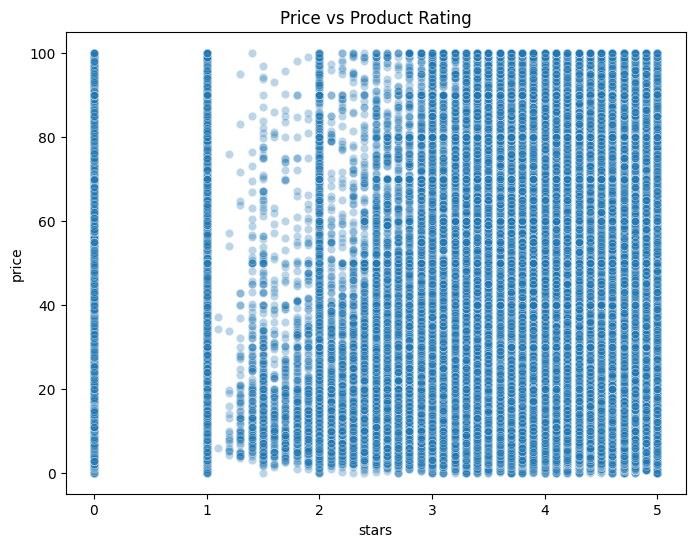

In [64]:
plt.figure(figsize=(8,6))

sns.scatterplot(
    data=df_no_outliers,
    x='stars',
    y='price',
    alpha=0.3
)

plt.title('Price vs Product Rating')
plt.show()

The scatter plot shows no clear linear relationship between product ratings and prices. Products with similar ratings can have vastly different prices, suggesting that rating alone is not a strong determinant of product price.

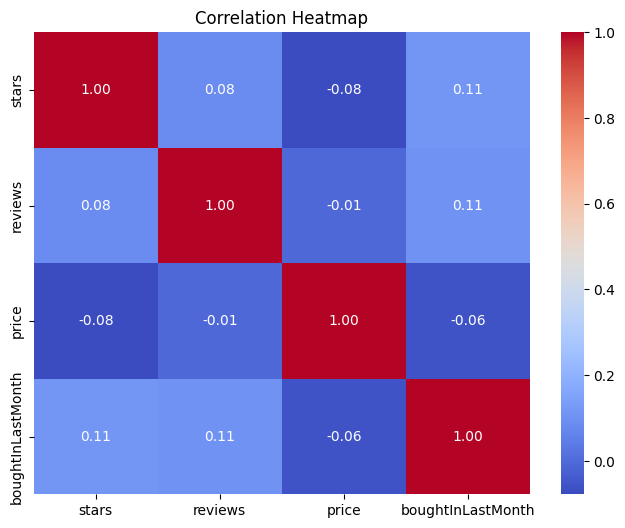

In [65]:
num_cols = [
    'stars',
    'reviews',
    'price',
    'boughtInLastMonth'
]

corr_matrix = (
    df_no_outliers[num_cols]
    .corr()
)

plt.figure(figsize=(8,6))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')
plt.show()

None of the numerical variables exhibit a strong correlation with one another.

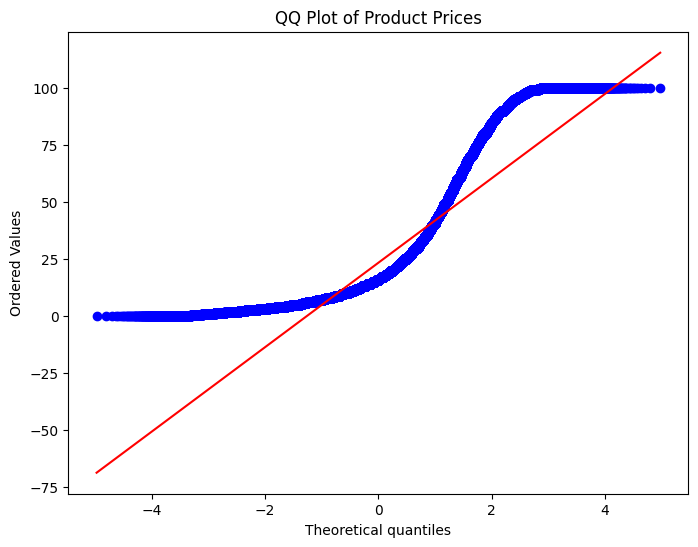

In [66]:
from scipy import stats

plt.figure(figsize=(8,6))

stats.probplot(
    df_no_outliers['price'],
    dist="norm",
    plot=plt
)

plt.title('QQ Plot of Product Prices')
plt.show()

The QQ plot indicates that product prices do not follow a normal distribution. The substantial deviation from the reference line suggests that the price distribution is highly skewed and non-normal.

In [67]:
corr_raw = df['price'].corr(df['stars'])

corr_clean = (
    df_no_outliers['price']
    .corr(df_no_outliers['stars'])
)

print(corr_raw)
print(corr_clean)

-0.12490673262149321
-0.07767299878181001


The negative correlation becomes slightly stronger when outliers are included. This suggests that extreme-priced products may exert additional influence on the observed relationship between price and ratings.

